# NDVI and land cover change in Tinigua National Natural Park (Colombia)

**Question:** how much did vegetation (Sentinel-2 NDVI) drop inside Tinigua National Natural Park between the dry seasons of 2019 and 2025, on which land cover, and how did it evolve year by year?

**Rule of this project:** the CRS of every layer is checked before any area, distance or buffer calculation, and every result states the CRS used and how many pixels had valid data.

**Tooling:** Sentinel-2 bands are read in place from public COGs with [terrio](https://github.com/opengeos/terrio) (pure Rust, no GDAL). Because terrio is young (v0.x), section 4 cross-checks it against GDAL on real data before using it.

## 0. Setup

Works both locally and in Google Colab. In Colab the repository is cloned so that `src/` can be imported, and the libraries that Colab does not preinstall are added.

In [1]:
import sys, os, subprocess

REPO = "ndvi-sentinel2-redd"  # replace with the repository name
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    # Colab only opens the notebook: clone the repo once and work from its root.
    # Safe to run again or after "Restart session".
    if os.path.basename(os.getcwd()) != REPO:
        if not os.path.exists(REPO):
            subprocess.run(["git", "clone", f"https://github.com/albertolozada/{REPO}.git"], check=True)
        os.chdir(REPO)
    # Libraries not preinstalled in Colab
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "terrio[xarray]", "pystac-client", "rioxarray",
                    "contextily", "matplotlib-scalebar"], check=True)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt
import terrio
from terrio.rio.enums import Resampling

from src.geo_checks import check_crs, to_metric, area_ha
from src.maps import plot_aoi_map
from src import s2, sources
from src.validation import compare_window, gfc_loss_on_grid, gfc_loss_by_year, compare_loss

print("terrio", terrio.__version__)

terrio 0.8.0


### Parameters

Change these to reuse the notebook for another protected area or period. Seasons are named by the year they end: the 2019 dry season runs from December 2018 to March 2019.

In [2]:
AREA_NAME = "Tinigua"                     # part of the name in RUNAP
AREA_CATEGORY = "Parque Nacional Natural"

BEFORE, AFTER = 2019, 2025                # dry seasons compared
SERIES_YEARS = list(range(2019, 2026))    # dry seasons in the time series
DRY_MONTHS = [12, 1, 2, 3]                # dry season in the north-west Amazon (Meta)

MAX_CLOUD = 60      # % scene cloud cover in the STAC search (clouds are masked per pixel later)
RES_MAIN = 40       # m, grid of the before/after comparison
RES_SERIES = 100    # m, grid of the time series (coarser = faster)

NDVI_FOREST = 0.6   # normalised NDVI before, above which a pixel is treated as dense vegetation
REF_NDVI = 0.7      # NDVI above which WorldCover tree cover is taken as stable reference forest
LOSS_DROP = -0.2    # normalised NDVI change below which a dense-vegetation pixel is flagged as loss
WATER_CLASS = 80    # ESA WorldCover permanent water, excluded from loss (river channels move)

GFC_YEARS = (2019, 2024)  # Hansen GFC loss years compared with the 2019-2025 dry-season change

os.makedirs("data", exist_ok=True)
os.makedirs("outputs/maps", exist_ok=True)

def season(year):
    """STAC datetime range of the dry season that ends in `year`."""
    return f"{year - 1}-12-01/{year}-03-31"

## 1. Load the study area

The official boundary comes from RUNAP (Registro Único Nacional de Áreas Protegidas, Parques Nacionales Naturales de Colombia). It is downloaded once and cached in `data/`, which is not versioned. If the service does not answer, the notebook uses the copy versioned in `data/sample/`.

In [3]:
aoi = sources.load_runap(AREA_NAME, AREA_CATEGORY,
                         cache="data/aoi.geojson",
                         fallback="data/sample/aoi_tinigua_runap.geojson")
print(len(aoi), "feature(s)")
aoi.drop(columns="geometry")

1 feature(s)


,ap_nombre,ap_categoria,fecha_inscrita,area_ha_total_resolucion,area_ha_terrestre_resolucion,area_ha_total_geografica
0,Tinigua,Parque Nacional Natural,1310533200000,207793.5,207793.5,207793.503042


## 2. Check the CRS and the area

RUNAP serves the layer in geographic coordinates (degrees), so it is reprojected to its UTM zone before measuring. The calculated area is compared with the area in the declaration resolution.

In [4]:
check_crs(aoi, "aoi (RUNAP)")

{'layer': 'aoi (RUNAP)',
 'crs': 'EPSG:4326',
 'is_geographic': True,
 'units': 'degree',
 'features': 1,
 'empty_geometries': 0,
 'missing_geometries': 0,
 'invalid_geometries': 0}

In [5]:
CRS = aoi.estimate_utm_crs().to_string()
aoi_m = to_metric(aoi, CRS)
print("CRS used for measurements and for the analysis grid:", CRS)

area_calc = float(area_ha(aoi_m).sum())
area_decl = float(aoi["area_ha_total_resolucion"].sum())
print(f"Calculated area ({CRS}): {area_calc:,.1f} ha")
print(f"Area in the RUNAP resolution field: {area_decl:,.1f} ha")
print(f"Difference: {area_calc - area_decl:,.1f} ha ({100 * (area_calc - area_decl) / area_decl:.2f} %)")
check_crs(aoi_m, "aoi (metric)")

CRS used for measurements and for the analysis grid: EPSG:32618
Calculated area (EPSG:32618): 207,923.3 ha
Area in the RUNAP resolution field: 207,793.5 ha
Difference: 129.8 ha (0.06 %)


{'layer': 'aoi (metric)',
 'crs': 'EPSG:32618',
 'is_geographic': False,
 'units': 'metre',
 'features': 1,
 'empty_geometries': 0,
 'missing_geometries': 0,
 'invalid_geometries': 0}

### Location map

Study area over a satellite basemap, with scale bar, north arrow and basemap attribution.

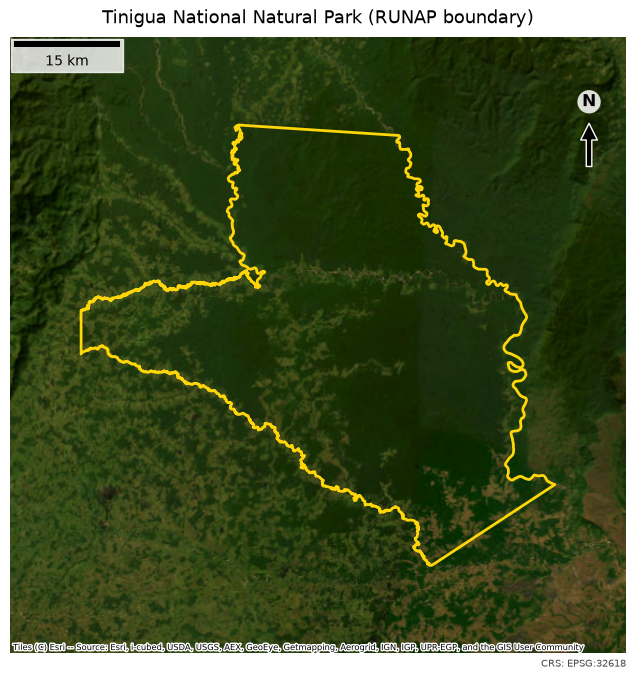

In [6]:
plot_aoi_map(aoi, out_png="outputs/maps/location_map.png", basemap="satellite",
             title="Tinigua National Natural Park (RUNAP boundary)", dpi=120)
plt.show()

## 3. Find Sentinel-2 scenes

Sentinel-2 L2A (surface reflectance) from the [Earth Search](https://earth-search.aws.element84.com/v1) STAC API, dry season only. The table lists every scene used, so the result can be traced back to its inputs.

In [7]:
bbox = tuple(aoi.total_bounds)  # EPSG:4326
items_before = s2.search_items(bbox, season(BEFORE), MAX_CLOUD, DRY_MONTHS)
items_after = s2.search_items(bbox, season(AFTER), MAX_CLOUD, DRY_MONTHS)
print(f"{BEFORE}: {len(items_before)} scenes | {AFTER}: {len(items_after)} scenes")
s2.items_table(items_before + items_after)

2019: 85 scenes | 2025: 77 scenes


,id,date,mgrs_tile,cloud_cover_%,processing_baseline,boa_offset_applied
0,S2A_18NXJ_20181202_0_L2A,2018-12-02,MGRS-18NXJ,18.4,00.01,False
1,S2A_18NXH_20181202_0_L2A,2018-12-02,MGRS-18NXH,13.8,00.01,False
2,S2A_18NWH_20181202_0_L2A,2018-12-02,MGRS-18NWH,0.1,00.01,False
3,S2A_18NXJ_20181205_0_L2A,2018-12-05,MGRS-18NXJ,46.9,00.01,False
4,S2A_18NXH_20181205_0_L2A,2018-12-05,MGRS-18NXH,6.7,00.01,False
...,...,...,...,...,...,...
157,S2A_18NWH_20250325_0_L2A,2025-03-25,MGRS-18NWH,16.6,05.11,True
158,S2B_18NXJ_20250328_0_L2A,2025-03-28,MGRS-18NXJ,54.7,05.11,True
159,S2B_18NXH_20250328_0_L2A,2025-03-28,MGRS-18NXH,59.5,05.11,True
160,S2C_18NXJ_20250330_0_L2A,2025-03-30,MGRS-18NXJ,19.9,05.11,True


## 4. Cross-check terrio against GDAL

The same 5 x 5 km window of one red band is read with terrio and with rioxarray (GDAL), at native resolution and without resampling, from the least cloudy scene that covers the centre of the park. Both should return identical pixels.

In [8]:
import terrio.xarray as txr
from pyproj import Transformer
from shapely.geometry import Point, shape

# Centre of the park, in EPSG:4326, to pick a scene that actually covers it
cx, cy = aoi_m.geometry.union_all().centroid.coords[0]
lon, lat = Transformer.from_crs(CRS, "EPSG:4326", always_xy=True).transform(cx, cy)

# Each Sentinel-2 item is one 100 x 100 km MGRS tile: use the least cloudy one that contains the centre
covering = [i for i in items_after if shape(i.geometry).contains(Point(lon, lat))]
if not covering:
    raise ValueError("No scene of the after season covers the centre of the park")
item = min(covering, key=lambda i: i.properties.get("eo:cloud_cover", 100))

href = item.assets["red"].href
item_crs = txr.open_rasterio(href).terrio.crs.to_string()  # CRS of the scene itself

# a 5 x 5 km window centred on the park, in the CRS of the scene
x, y = Transformer.from_crs("EPSG:4326", item_crs, always_xy=True).transform(lon, lat)
check = compare_window(href, (x - 2500, y - 2500, x + 2500, y + 2500), item_crs)
print(item.id, "| cloud cover", item.properties.get("eo:cloud_cover"), "%")
check

S2C_18NWH_20250122_0_L2A | cloud cover 0.096076 %


{'terrio_shape': (501, 501),
 'gdal_shape': (501, 501),
 'same_shape': True,
 'pixels': 251001,
 'identical_%': 100.0,
 'max_abs_diff': 0.0}

## 5. Dry-season NDVI composites (before and after)

For each scene, red (B04) and NIR (B08) are read from the COG overview closest to the grid size, converted to reflectance, masked with the Scene Classification Layer and resampled onto one grid. Earth Search splits each acquisition into overlapping MGRS tiles, so the tiles of the same acquisition are merged first and every date weighs the same. The composite is the per-pixel median over the clear dates.

Products processed with baseline 04.00 or later (from 25 January 2022) can carry a +1000 DN offset, and the STAC metadata does not always state it consistently with the stored values. The offset is therefore decided per scene from the pixels: it is subtracted when the 5th percentile of clear red DN is 1000 or more. The log below records the declared and the applied offset of every scene.

In [9]:
grid = s2.make_grid(aoi, CRS, RES_MAIN)
print(f"Grid: {grid.shape[1]} x {grid.shape[0]} pixels of {grid.res} m, {grid.crs}")

before, log_before = s2.composite(items_before, grid, aoi)
after, log_after = s2.composite(items_after, grid, aoi)

print(f"Clear acquisition dates: {BEFORE} {before.attrs['dates']} | {AFTER} {after.attrs['dates']}")

Grid: 1680 x 1561 pixels of 40 m, EPSG:32618
[1/85] S2A_18NXJ_20181202_0_L2A: ok, clear 99.7%
[2/85] S2A_18NXH_20181202_0_L2A: ok, clear 99.7%
[3/85] S2A_18NWH_20181202_0_L2A: ok, clear 100.0%
[4/85] S2A_18NXJ_20181205_0_L2A: ok, clear 87.3%
[5/85] S2A_18NXH_20181205_0_L2A: ok, clear 92.1%
[6/85] S2A_18NWH_20181205_0_L2A: ok, clear 85.9%
[7/85] S2B_18NXJ_20181207_0_L2A: ok, clear 90.9%
[8/85] S2B_18NXH_20181207_0_L2A: ok, clear 89.8%
[9/85] S2B_18NWH_20181207_0_L2A: ok, clear 91.6%
[10/85] S2B_18NXH_20181210_0_L2A: ok, clear 49.7%
[11/85] S2B_18NWH_20181210_0_L2A: ok, clear 52.7%
[12/85] S2A_18NXJ_20181215_0_L2A: ok, clear 94.3%
[13/85] S2A_18NWJ_20181215_0_L2A: ok, clear 92.6%
[14/85] S2A_18NXH_20181215_0_L2A: ok, clear 79.4%
[15/85] S2A_18NWH_20181215_0_L2A: ok, clear 81.4%
[16/85] S2B_18NXJ_20181217_0_L2A: ok, clear 24.8%
[17/85] S2B_18NWH_20181217_0_L2A: ok, clear 9.1%
[18/85] S2A_18NXJ_20181222_0_L2A: ok, clear 79.8%
[19/85] S2A_18NXH_20181222_0_L2A: ok, clear 24.2%
[20/85] S2A_18

In [10]:
pd.concat([log_before, log_after])  # per scene: declared and applied offset, clear pixels

,id,date,status,baseline,metadata_offset,red_p5_dn,offset_applied_dn,pixels_in_scene,clear_%,acquisition
0,S2A_18NXJ_20181202_0_L2A,2018-12-02,ok,0.01,0.0,256.0,0,113137,99.7,2018-12-02 sentinel-2a
1,S2A_18NXH_20181202_0_L2A,2018-12-02,ok,0.01,0.0,267.0,0,672279,99.7,2018-12-02 sentinel-2a
2,S2A_18NWH_20181202_0_L2A,2018-12-02,ok,0.01,0.0,271.0,0,148605,100.0,2018-12-02 sentinel-2a
3,S2A_18NXJ_20181205_0_L2A,2018-12-05,ok,0.01,0.0,186.0,0,220426,87.3,2018-12-05 sentinel-2a
4,S2A_18NXH_20181205_0_L2A,2018-12-05,ok,0.01,0.0,213.0,0,857646,92.1,2018-12-05 sentinel-2a
...,...,...,...,...,...,...,...,...,...,...
72,S2B_18NWH_20250325_1_L2A,2025-03-25,ok,5.11,-0.1,341.0,0,200735,39.0,2025-03-25 sentinel-2b
73,S2B_18NXJ_20250328_0_L2A,2025-03-28,ok,5.11,-0.1,549.0,0,220426,57.7,2025-03-28 sentinel-2b
74,S2B_18NXH_20250328_0_L2A,2025-03-28,ok,5.11,-0.1,585.0,0,833554,42.1,2025-03-28 sentinel-2b
75,S2C_18NXJ_20250330_0_L2A,2025-03-30,ok,5.11,-0.1,460.0,0,129870,59.2,2025-03-30 sentinel-2c


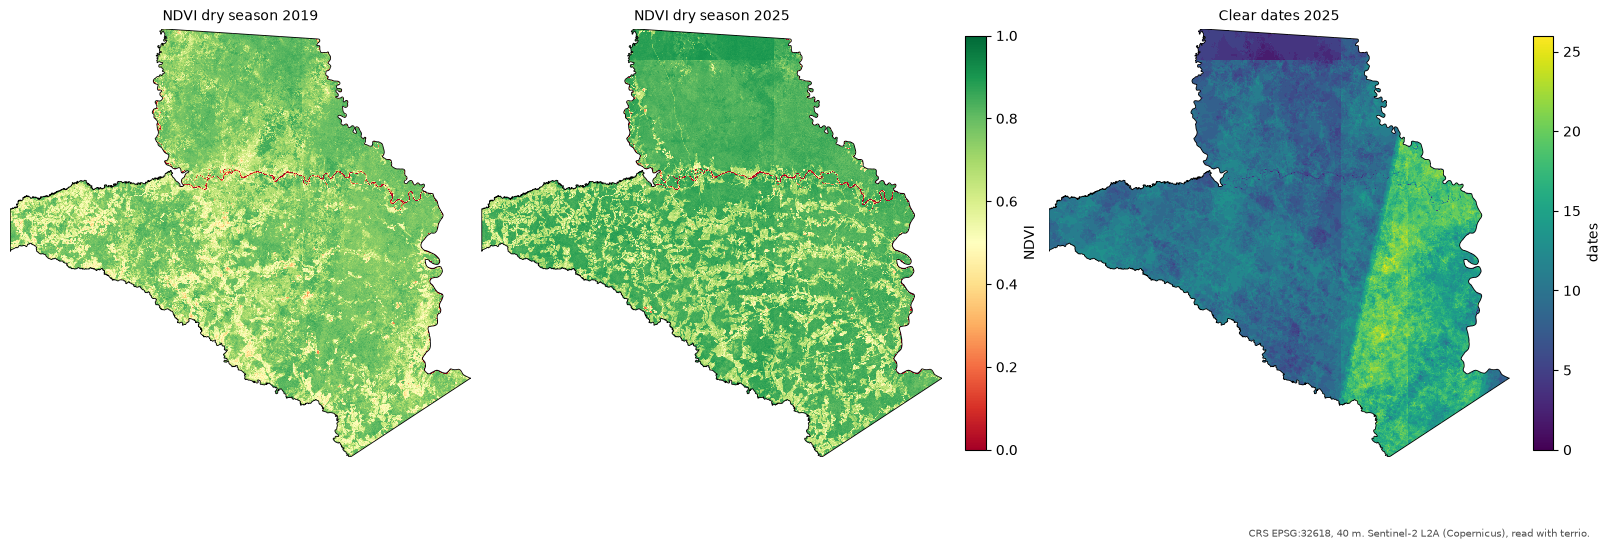

In [11]:
def show(ax, da, title, **kw):
    b = grid.bounds
    im = ax.imshow(da.values, extent=(b[0], b[2], b[1], b[3]), interpolation="nearest", **kw)
    aoi_m.boundary.plot(ax=ax, color="black", linewidth=0.6)
    ax.set_title(title, fontsize=10)
    ax.set_axis_off()
    return im

fig, axes = plt.subplots(1, 3, figsize=(16, 6), layout="constrained")
show(axes[0], before.ndvi, f"NDVI dry season {BEFORE}", cmap="RdYlGn", vmin=0, vmax=1)
im = show(axes[1], after.ndvi, f"NDVI dry season {AFTER}", cmap="RdYlGn", vmin=0, vmax=1)
fig.colorbar(im, ax=axes[1], shrink=0.7, label="NDVI")
im2 = show(axes[2], after.n_clear, f"Clear dates {AFTER}", cmap="viridis")
fig.colorbar(im2, ax=axes[2], shrink=0.7, label="dates")
fig.text(0.99, 0.01, f"CRS {CRS}, {grid.res} m. Sentinel-2 L2A (Copernicus), read with terrio.",
         ha="right", fontsize=7, color="0.3")
plt.savefig("outputs/maps/ndvi_before_after.png", dpi=120, bbox_inches="tight")
plt.show()

## 6. Land cover and reference forest

ESA WorldCover 10 m 2021 is resampled onto the grid with the majority (mode) rule, read at full resolution because averaged overviews would mix class codes.

Surface reflectance from different years is not perfectly comparable: processing baselines, atmospheric correction, haze and sun angle shift NDVI over the whole scene. The comparison therefore uses **reference forest** (pseudo-invariant pixels): WorldCover tree cover with NDVI above `REF_NDVI` in both seasons. Its NDVI is assumed constant, and its median shift between seasons is removed before measuring change.

In [12]:
def read_worldcover(g):
    out = None
    for url in sources.worldcover_urls(aoi.total_bounds):
        part = s2.read_to_grid(url, g, Resampling.mode)
        if part is not None:
            out = part if out is None else out.fillna(part)
    return s2.mask_to_aoi(out, aoi, g)

print("\n".join(sources.worldcover_urls(aoi.total_bounds)))
wc = read_worldcover(grid)

reference = s2.stable_forest([before.ndvi, after.ndvi], wc, min_ndvi=REF_NDVI)
ref_before = s2.reference_ndvi(before.ndvi, reference)
ref_after = s2.reference_ndvi(after.ndvi, reference)
shift = ref_after - ref_before
print(f"Reference forest: {float(reference.sum()) * grid.pixel_area_ha:,.0f} ha")
print(f"Median NDVI of the reference forest: {BEFORE} {ref_before:.3f} | {AFTER} {ref_after:.3f} "
      f"| shift removed {shift:+.3f}")

https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/ESA_WorldCover_10m_2021_v200_N00W075_Map.tif
Reference forest: 122,221 ha
Median NDVI of the reference forest: 2019 0.775 | 2025 0.840 | shift removed +0.064


## 7. NDVI change and potential vegetation loss

The change is measured after removing the reference-forest shift. A pixel is flagged as **potential vegetation loss** when its NDVI was above `NDVI_FOREST` in the first season and the normalised change is below `LOSS_DROP`. Permanent water in WorldCover is excluded, because moving river channels change NDVI without any vegetation loss. This is a signal to look at, not a deforestation map: NDVI also changes with phenology, drought, fire, residual clouds or regrowth.

In [13]:
dndvi = (after.ndvi - before.ndvi) - shift
not_water = wc != WATER_CLASS
loss = (before.ndvi > NDVI_FOREST) & (dndvi < LOSS_DROP) & not_water
both = before.ndvi.notnull() & after.ndvi.notnull()

loss_ha = float(loss.sum()) * grid.pixel_area_ha
compared_ha = float(both.sum()) * grid.pixel_area_ha
print(f"Pixels with valid NDVI in both seasons: {compared_ha:,.0f} ha "
      f"({100 * compared_ha / area_calc:.1f} % of the calculated area)")
print(f"Potential vegetation loss {BEFORE}-{AFTER}: {loss_ha:,.0f} ha "
      f"(grid {grid.res} m, {CRS}, reference shift {shift:+.3f})")

Pixels with valid NDVI in both seasons: 207,926 ha (100.0 % of the calculated area)
Potential vegetation loss 2019-2025: 7,629 ha (grid 40 m, EPSG:32618, reference shift +0.064)


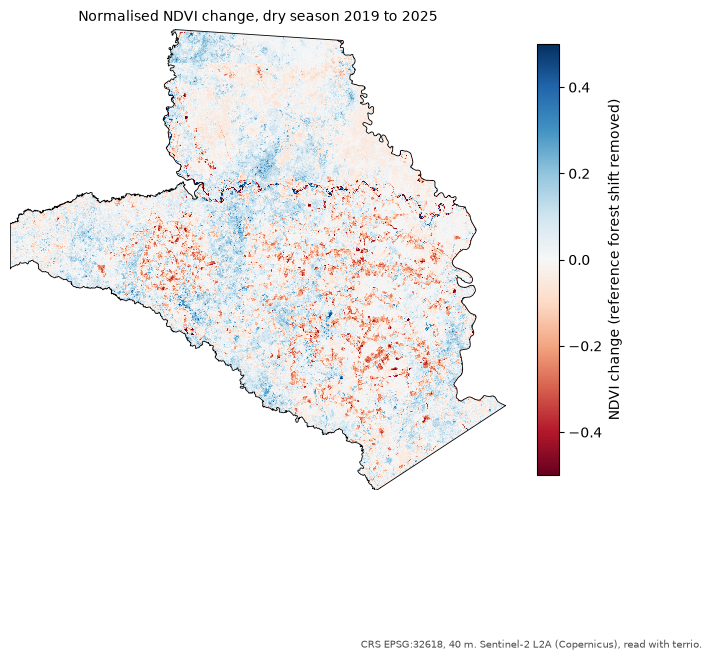

In [14]:
fig, ax = plt.subplots(figsize=(8, 8))
im = show(ax, dndvi, f"Normalised NDVI change, dry season {BEFORE} to {AFTER}", cmap="RdBu", vmin=-0.5, vmax=0.5)
fig.colorbar(im, ax=ax, shrink=0.7, label="NDVI change (reference forest shift removed)")
fig.text(0.99, 0.01, f"CRS {CRS}, {grid.res} m. Sentinel-2 L2A (Copernicus), read with terrio.",
         ha="right", fontsize=7, color="0.3")
plt.savefig("outputs/maps/ndvi_change.png", dpi=120, bbox_inches="tight")
plt.savefig("outputs/maps/preview.png", dpi=100, bbox_inches="tight")  # image under the README title
plt.show()

## 8. Land cover of the change

Potential loss by ESA WorldCover 2021 class.

In [15]:
inside = np.isfinite(wc.values)
table = pd.DataFrame({"class": wc.values[inside].astype(int), "loss": loss.values[inside]})
by_class = table.groupby("class").agg(area_ha=("loss", "size"), loss_ha=("loss", "sum"))
by_class *= grid.pixel_area_ha
by_class["loss_%_of_class"] = (100 * by_class["loss_ha"] / by_class["area_ha"]).round(2)
by_class.insert(0, "name", sources.class_names(by_class.index))
by_class.round(1)

,name,area_ha,loss_ha,loss_%_of_class
class,,,,
10,Tree cover,167896.5,5436.0,3.2
20,Shrubland,2.1,0.6,30.8
30,Grassland,38418.9,2182.6,5.7
40,Cropland,1.8,0.8,45.4
50,Built-up,5.0,0.0,0.0
60,Bare / sparse vegetation,137.4,8.5,6.2
80,Permanent water bodies,1463.5,0.0,0.0
90,Herbaceous wetland,2.1,0.5,23.1


## 9. Independent check with Hansen Global Forest Change

Hansen / UMD Global Forest Change v1.13 maps yearly tree cover loss from Landsat at about 30 m. Its loss for `GFC_YEARS` is read with terrio, resampled to the share of each 40 m cell that was lost, and a cell counts as GFC loss when at least half of it was lost. The two maps are compared only where our method can detect loss (NDVI above `NDVI_FOREST` in the first season, no permanent water).

The methods differ (Landsat vs Sentinel-2, calendar years vs dry seasons, tree cover loss vs NDVI drop), so full agreement is not expected. "Confirmed" is the share of our loss that GFC also maps; "detected" is the share of GFC loss that we find. The 1-pixel columns accept a match in a neighbouring cell, which absorbs small misregistration between the two sensors.

In [16]:
gfc_urls = sources.gfc_urls(aoi.total_bounds, "lossyear")
print("\n".join(gfc_urls))
gfc_share = s2.mask_to_aoi(gfc_loss_on_grid(gfc_urls, grid, *GFC_YEARS), aoi, grid)
gfc_loss = gfc_share >= 0.5

domain = (before.ndvi > NDVI_FOREST) & not_water & gfc_share.notnull()
agreement = compare_loss(loss.values, gfc_loss.values, domain.values, grid.pixel_area_ha)
pd.Series(agreement, name=f"NDVI loss {BEFORE}-{AFTER} vs GFC {GFC_YEARS[0]}-{GFC_YEARS[1]}")

https://storage.googleapis.com/earthenginepartners-hansen/GFC-2025-v1.13/Hansen_GFC-2025-v1.13_lossyear_10N_080W.tif


our_loss_ha                7629.0
gfc_loss_ha               31638.2
both_ha                    6212.5
confirmed_by_gfc_%           81.4
gfc_detected_%               19.6
confirmed_by_gfc_%_1px       89.0
gfc_detected_%_1px           40.9
Name: NDVI loss 2019-2025 vs GFC 2019-2024, dtype: float64

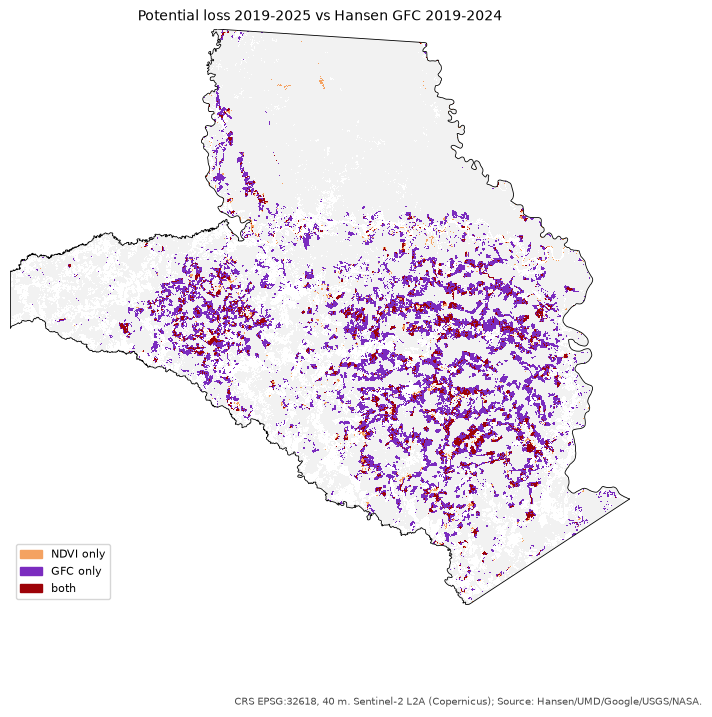

In [17]:
from matplotlib.colors import ListedColormap

cat = np.full(grid.shape, np.nan)
d = domain.values
cat[d] = 0
cat[d & loss.values & ~gfc_loss.values] = 1
cat[d & gfc_loss.values & ~loss.values] = 2
cat[d & loss.values & gfc_loss.values] = 3
cmap = ListedColormap(["#f2f2f2", "#f4a261", "#7b2cbf", "#9d0208"])

fig, ax = plt.subplots(figsize=(8, 8))
show(ax, xr.DataArray(cat), f"Potential loss {BEFORE}-{AFTER} vs Hansen GFC {GFC_YEARS[0]}-{GFC_YEARS[1]}",
     cmap=cmap, vmin=-0.5, vmax=3.5)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=l) for c, l in zip(cmap.colors[1:], ["NDVI only", "GFC only", "both"])],
          loc="lower left", fontsize=8)
fig.text(0.99, 0.01, f"CRS {CRS}, {grid.res} m. Sentinel-2 L2A (Copernicus); Source: Hansen/UMD/Google/USGS/NASA.",
         ha="right", fontsize=7, color="0.3")
plt.savefig("outputs/maps/loss_vs_gfc.png", dpi=120, bbox_inches="tight")
plt.show()

## 10. Year-by-year series (dry seasons)

The same composite on a coarser grid (`RES_SERIES`) for every dry season in `SERIES_YEARS`. The reference forest is the tree cover with NDVI above `REF_NDVI` in **every** season, and each season is shifted so that its reference forest matches the median of all seasons. Both the raw and the normalised values are reported; permanent water is left out of the low-NDVI area. This is the slowest step: expect several minutes per season.

In [18]:
grid_s = s2.make_grid(aoi, CRS, RES_SERIES)
wc_s = read_worldcover(grid_s)

seasons, n_scenes = {}, {}
for year in SERIES_YEARS:
    items = s2.search_items(bbox, season(year), MAX_CLOUD, DRY_MONTHS)
    seasons[year], _ = s2.composite(items, grid_s, aoi, verbose=False)
    n_scenes[year] = len(items)
    print(year, f"{len(items)} scenes, {seasons[year].attrs['dates']} acquisition dates")

2019 85 scenes, 28 acquisition dates
2020 158 scenes, 34 acquisition dates
2021 167 scenes, 31 acquisition dates
2022 93 scenes, 25 acquisition dates
2023 75 scenes, 31 acquisition dates
2024 65 scenes, 27 acquisition dates
2025 77 scenes, 30 acquisition dates


In [19]:
reference_s = s2.stable_forest([ds.ndvi for ds in seasons.values()], wc_s, min_ndvi=REF_NDVI)
refs = {y: s2.reference_ndvi(ds.ndvi, reference_s) for y, ds in seasons.items()}
target = float(np.median(list(refs.values())))
print(f"Reference forest in every season: {float(reference_s.sum()) * grid_s.pixel_area_ha:,.0f} ha")

rows = []
for y, ds in seasons.items():
    norm = ds.ndvi - (refs[y] - target)
    valid = np.isfinite(norm.values) & (wc_s.values != WATER_CLASS)
    rows.append({
        "season": y,
        "scenes": n_scenes[y],
        "dates": ds.attrs["dates"],
        "reference_ndvi_raw": round(refs[y], 3),
        "median_ndvi_raw": round(float(ds.ndvi.median()), 3),
        "median_ndvi_norm": round(float(norm.median()), 3),
        "ndvi_norm_lt_0.5_ha": round(float(((norm.values < 0.5) & valid).sum()) * grid_s.pixel_area_ha, 1),
    })
series = pd.DataFrame(rows).set_index("season")
series

Reference forest in every season: 88,464 ha


,scenes,dates,reference_ndvi_raw,median_ndvi_raw,median_ndvi_norm,ndvi_norm_lt_0.5_ha
season,,,,,,
2019,85,28,0.774,0.735,0.781,2253.0
2020,158,34,0.803,0.770,0.786,5872.0
2021,167,31,0.823,0.796,0.793,2709.0
2022,93,25,0.820,0.796,0.796,18403.0
2023,75,31,0.837,0.817,0.799,2447.0
2024,65,27,0.814,0.793,0.799,2223.0
2025,77,30,0.838,0.820,0.802,1368.0


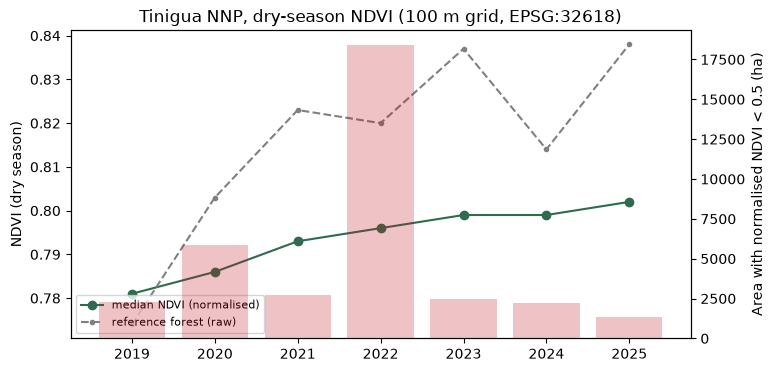

In [20]:
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(series.index, series["median_ndvi_norm"], marker="o", color="#2f6b4f", label="median NDVI (normalised)")
ax1.plot(series.index, series["reference_ndvi_raw"], marker=".", ls="--", color="0.5", label="reference forest (raw)")
ax1.set_ylabel("NDVI (dry season)")
ax1.legend(loc="lower left", fontsize=8)
ax2 = ax1.twinx()
ax2.bar(series.index, series["ndvi_norm_lt_0.5_ha"], alpha=0.25, color="#c1121f")
ax2.set_ylabel("Area with normalised NDVI < 0.5 (ha)")
ax1.set_title(f"Tinigua NNP, dry-season NDVI ({RES_SERIES} m grid, {CRS})")
plt.savefig("outputs/maps/ndvi_series.png", dpi=120, bbox_inches="tight")
plt.show()

### Close look at one season

The low-NDVI area of a single season can come from real burning or clearing, or from clouds and smoke that the scene classification missed, which is more likely when a season has few clear dates. The map compares the season with the largest low-NDVI area with the seasons before and after it, and shows its number of clear dates.

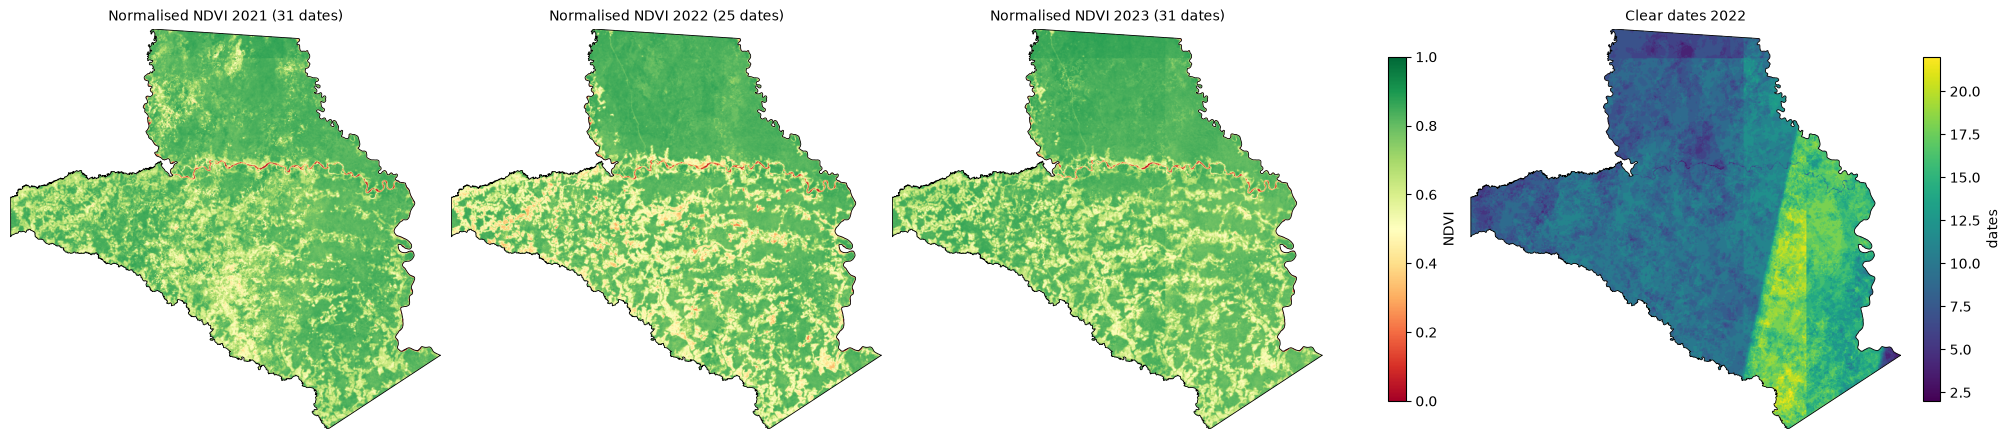

In [21]:
peak = int(series["ndvi_norm_lt_0.5_ha"].idxmax())
years = [y for y in (peak - 1, peak, peak + 1) if y in seasons]
b = grid_s.bounds
fig, axes = plt.subplots(1, len(years) + 1, figsize=(5 * (len(years) + 1), 5), layout="constrained")
for ax, y in zip(axes, years):
    norm = seasons[y].ndvi - (refs[y] - target)
    im = ax.imshow(norm.values, extent=(b[0], b[2], b[1], b[3]), cmap="RdYlGn", vmin=0, vmax=1)
    aoi_m.boundary.plot(ax=ax, color="black", linewidth=0.6)
    ax.set_title(f"Normalised NDVI {y} ({seasons[y].attrs['dates']} dates)", fontsize=10)
    ax.set_axis_off()
fig.colorbar(im, ax=axes[:len(years)], shrink=0.7, label="NDVI")
im2 = axes[-1].imshow(seasons[peak].n_clear.values, extent=(b[0], b[2], b[1], b[3]), cmap="viridis")
aoi_m.boundary.plot(ax=axes[-1], color="black", linewidth=0.6)
axes[-1].set_title(f"Clear dates {peak}", fontsize=10)
axes[-1].set_axis_off()
fig.colorbar(im2, ax=axes[-1], shrink=0.7, label="dates")
plt.savefig(f"outputs/maps/ndvi_season_{peak}.png", dpi=120, bbox_inches="tight")
plt.show()

## 11. Year-by-year loss and comparison with GFC

Comparing only the first and the last season misses vegetation that was cleared and then grew back (pasture or secondary vegetation) before the last season. Here a pixel is flagged when it had dense vegetation (`NDVI_FOREST`) in the first season and its normalised NDVI drops by more than `LOSS_DROP` below that value in a later season.

A drop seen in a single dry season can also come from a very dry or burnt season on pasture and scrub, without any loss of forest. So the drop must **persist in two consecutive seasons**; in the last season, which has no following one yet, a single drop is accepted. The season in which the persistent drop starts is kept. The table also shows the detection without persistence, for comparison.

The detections are compared with Hansen GFC on the same 100 m grid. GFC loss is then counted per calendar year inside the same domain: a drop first seen in the dry season ending in year *y* (December *y-1* to March *y*) happened mostly during calendar year *y-1*.

In [22]:
years = sorted(seasons)
first = years[0]
norms = {y: seasons[y].ndvi - (refs[y] - target) for y in years}
base = norms[first]
forest0 = (base > NDVI_FOREST) & (wc_s != WATER_CLASS)

drop = {y: forest0 & ((norms[y] - base) < LOSS_DROP) for y in years[1:]}

def first_season(persistent):
    """Season of the first drop; with persistence the drop must continue in the next season."""
    out = xr.full_like(base, np.nan)
    for k, y in enumerate(years[1:], start=1):
        hit = drop[y]
        if persistent and k < len(years) - 1:
            hit = hit & drop[years[k + 1]]
        out = out.where(~(hit & out.isnull()), y)
    return out

first_loss = first_season(persistent=True)
loss_persistent = first_loss.notnull()
loss_any = first_season(persistent=False).notnull()
loss_two = drop[years[-1]]

gfc_share_s = s2.mask_to_aoi(gfc_loss_on_grid(gfc_urls, grid_s, *GFC_YEARS), aoi, grid_s)
domain_s = forest0 & gfc_share_s.notnull()
gfc_loss_s = gfc_share_s >= 0.5

pd.DataFrame({
    f"two seasons ({first} vs {years[-1]})": compare_loss(loss_two.values, gfc_loss_s.values, domain_s.values, grid_s.pixel_area_ha),
    f"any season ({years[1]}-{years[-1]})": compare_loss(loss_any.values, gfc_loss_s.values, domain_s.values, grid_s.pixel_area_ha),
    "persistent (2 seasons)": compare_loss(loss_persistent.values, gfc_loss_s.values, domain_s.values, grid_s.pixel_area_ha),
})

,two seasons (2019 vs 2025),any season (2020-2025),persistent (2 seasons)
our_loss_ha,5009.0,26230.0,8791.0
gfc_loss_ha,33105.0,33105.0,33105.0
both_ha,4225.0,16206.0,7176.0
confirmed_by_gfc_%,84.3,61.8,81.6
gfc_detected_%,12.8,49.0,21.7
confirmed_by_gfc_%_1px,93.6,76.2,92.6
gfc_detected_%_1px,34.4,82.0,51.7


In [23]:
gfc_by_year = gfc_loss_by_year(gfc_urls, grid_s, range(first, years[-1]), domain=domain_s.values)
by_year = pd.DataFrame({
    "GFC loss in calendar year y-1 (ha)": [gfc_by_year.get(y - 1) for y in years[1:]],
    "persistent NDVI drop from dry season y (ha)": [round(float((first_loss == y).sum()) * grid_s.pixel_area_ha, 1)
                                                  for y in years[1:]],
}, index=pd.Index(years[1:], name="y"))
by_year

,GFC loss in calendar year y-1 (ha),persistent NDVI drop from dry season y (ha)
y,,
2020,4867.2,1139.0
2021,8384.5,1210.0
2022,4553.0,3203.0
2023,6794.2,569.0
2024,680.0,667.0
2025,4413.5,2003.0


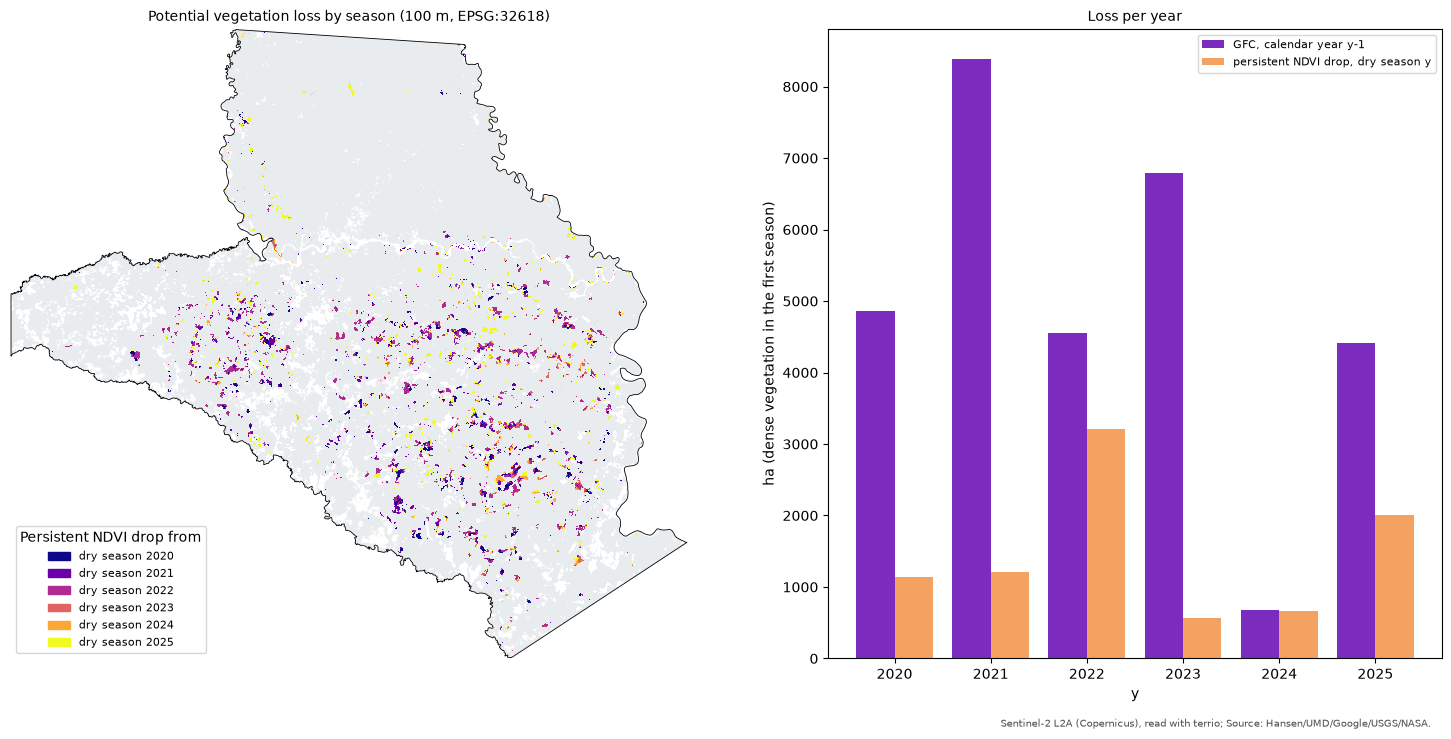

In [24]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

seasons_lost = years[1:]
colours = plt.get_cmap("plasma", len(seasons_lost)).colors
b = grid_s.bounds
fig, (ax, axb) = plt.subplots(1, 2, figsize=(15, 7), layout="constrained",
                               gridspec_kw={"width_ratios": [1.3, 1]})
ax.imshow(np.where(forest0.values, 0, np.nan), extent=(b[0], b[2], b[1], b[3]), cmap=ListedColormap(["#e9ecef"]))
ax.imshow(first_loss.values, extent=(b[0], b[2], b[1], b[3]), interpolation="nearest",
          cmap=ListedColormap(colours), norm=BoundaryNorm([y - 0.5 for y in seasons_lost] + [seasons_lost[-1] + 0.5], len(seasons_lost)))
aoi_m.boundary.plot(ax=ax, color="black", linewidth=0.6)
ax.legend(handles=[Patch(color=c, label=f"dry season {y}") for c, y in zip(colours, seasons_lost)],
          loc="lower left", fontsize=8, title="Persistent NDVI drop from")
ax.set_title(f"Potential vegetation loss by season ({RES_SERIES} m, {CRS})", fontsize=10)
ax.set_axis_off()

x = np.arange(len(seasons_lost))
axb.bar(x - 0.2, by_year.iloc[:, 0], 0.4, color="#7b2cbf", label="GFC, calendar year y-1")
axb.bar(x + 0.2, by_year.iloc[:, 1], 0.4, color="#f4a261", label="persistent NDVI drop, dry season y")
axb.set_xticks(x, [str(y) for y in seasons_lost])
axb.set_xlabel("y")
axb.set_ylabel("ha (dense vegetation in the first season)")
axb.legend(fontsize=8)
axb.set_title("Loss per year", fontsize=10)
fig.text(0.99, -0.03, "Sentinel-2 L2A (Copernicus), read with terrio; Source: Hansen/UMD/Google/USGS/NASA.",
         ha="right", fontsize=7, color="0.3")
plt.savefig("outputs/maps/loss_by_season.png", dpi=120, bbox_inches="tight")
plt.show()

## 12. Results and limitations

- **Boundary and area:** 207,923 ha in EPSG:32618, 130 ha (0.06 %) more than the 207,794 ha recorded in RUNAP.
- **terrio vs GDAL:** 251,001 pixels of a Sentinel-2 red band, 100 % identical.
- **Reference forest shift:** 122,221 ha of reference forest; median NDVI 0.775 in 2019 and 0.840 in 2025, so +0.064 was removed before measuring change (88,464 ha of reference forest in every season of the series).
- **Main result:** 7,629 ha of potential vegetation loss between the dry seasons of 2019 and 2025 (40 m grid), 3.7 % of the park: 5,436 ha on WorldCover tree cover (3.2 % of that class) and 2,183 ha on grassland (5.7 %).
- **Agreement with Hansen GFC (2019-2024):** 81.4 % of the 2019-2025 loss is also mapped by GFC (89.0 % with one pixel of tolerance), but it covers only 19.6 % of GFC loss (40.9 %). On the 100 m series, a drop in any season finds 49.0 % of GFC loss (82.0 % with tolerance) at 61.8 % confirmation; requiring the drop to persist two seasons keeps confirmation at 81.6 % (92.6 %) and finds 21.7 % (51.7 %).
- **Year by year:** GFC loss inside the 2019 dense vegetation was 4,867, 8,385, 4,553, 6,794, 680 and 4,414 ha in 2019-2024. Persistent NDVI drops start mostly in the dry seasons of 2022 (3,203 ha) and 2025 (2,003 ha), one to two years after GFC records the loss.
- **Dry-season series:** the area with normalised NDVI below 0.5 (water excluded) was 2,253 ha in 2019, peaked at 18,403 ha in 2022 and fell to 1,368 ha in 2025. The 2022 low values follow the existing pasture mosaic, not cloud shapes, and appear where the season had 15 to 20 clear dates: an unusually dry or burnt season on land that was already open.
- **Completeness:** valid NDVI in both seasons on 100 % of the park; every scene in the search was read (status "ok" in the log of section 5).
- **CRS used:** EPSG:32618 (WGS 84 / UTM zone 18N) for every area and for all analysis grids.
- **Limitations:**
  - NDVI loss is not deforestation: dry-season NDVI flags mostly real loss, but misses clearings that turn into green pasture or regrowth before the next dry season. It works as a screening of where to look, not as a replacement for loss mapping; official data (IDEAM, SMByC) remain the reference for Colombia.
  - The dry-season composites see a clearing later than the annual Landsat product, so yearly figures should be compared as trends, not year by year.
  - Persistent cloud in the Amazon leaves some pixels with few clear dates, especially in the north-west of the park.
  - ESA WorldCover is a single date (2021), between the two seasons compared.
  - Normalisation assumes the reference forest did not change; degradation inside it would be partly removed.
  - Results depend on the grid size and on the thresholds `NDVI_FOREST`, `REF_NDVI` and `LOSS_DROP`.